# Taller 2: Métodos de Ensamble y Evaluación de Modelos
**Materia:** Aprendizaje Avanzado  
**Autor:** Miguel Ángel Ortiz Roldán  
**Archivo de Entrega:** `Taller2_MiguelAngelOrtiz.ipynb`  
**Link Colab:** *
**Video Explicativo:** *  

---

## 1. Introducción

En este taller trabajamos con dos tipos de problemas fundamentales del aprendizaje automático supervisado:
1. **Punto 1 - Clasificación:** Resolver un problema financiero del mundo real utilizando el dataset **Bank Marketing (UCI)**. El objetivo es predecir si un cliente suscribirá o no un depósito a plazo fijo bancario (`y`: yes/no) a partir de sus atributos demográficos, historial financiero y detalles de la campaña de contacto.
2. **Punto 2 - Regresión:** Predecir cuantitativamente una propiedad física continua con el dataset **Concrete Compressive Strength (UCI)**. El objetivo es estimar con alta precisión la resistencia a la compresión del concreto en megapascales (MPa) según la mezcla de sus 8 componentes físicos y el tiempo de curado.

Para resolver ambos problemas utilizamos **Métodos de Ensamble (*Ensemble Learning*)**. La idea central detrás de esta técnica es intuitiva y se conoce como **"la sabiduría de las masas"** (*wisdom of the crowd*): en lugar de confiar en el criterio de un único modelo, consultamos a un grupo o equipo de estimadores y combinamos sus respuestas. En aprendizaje automático, un grupo de modelos trabajando en conjunto casi siempre toma mejores decisiones y generaliza con mayor solidez que el mejor modelo trabajando por separado.

Siguiendo rigurosamente las pautas de la guía académica del taller, en este informe:
- Comparamos un árbol de decisión base individual contra tres técnicas de ensamble en Scikit-Learn: **Random Forest (Bagging)**, **AdaBoost (Boosting)** y **Gradient Boosting (Boosting)**.
- Implementamos dos métodos formales de búsqueda de hiperparámetros: **RandomizedSearchCV** (exploración amplia y ágil) y **GridSearchCV** (afinamiento exhaustivo en rejilla).
- Evaluamos los modelos con Validación Cruzada (K-Fold) y los ponemos a prueba con un conjunto de datos ciego (*Test Set*) nunca antes visto durante el entrenamiento.
- Analizamos visualmente matrices de confusión, curvas ROC, análisis de residuos y la importancia relativa de variables (*Feature Importance*).

---

## 2. Marco Teórico

> **Fuente y lectura de referencia:** Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (O'Reilly Media). Capítulo 7 (*Ensemble Learning and Random Forests*) y Capítulo 2 (*End-to-End Machine Learning Project*).

### 2.1 ¿Qué son los métodos de ensamble y por qué funcionan?
Un ensamble es un grupo de modelos que trabajan juntos para dar una sola respuesta. La idea se resume en una frase muy conocida: "la sabiduría de las masas". Cuando le preguntamos a muchas personas y juntamos sus respuestas, el resultado suele ser mejor que la opinión de una sola persona, por más experta que sea.

Con los modelos pasa lo mismo. Un modelo se puede equivocar en unos datos y otro modelo se equivoca en datos distintos. Si juntamos a varios y los hacemos votar (o promediar sus respuestas), los errores de unos se compensan con los aciertos de otros, y la respuesta final es más confiable que la de cualquier modelo por separado.

Un ejemplo sencillo: imagina una moneda con un 51% de probabilidad de caer en "cara". Si la lanzas una sola vez, el resultado es pura suerte. Pero si la lanzas 1.000 veces, es casi seguro que la mayoría de los lanzamientos saldrán "cara". Ese es el mismo principio: una decisión aislada es incierta, pero muchas decisiones juntas tienden a acertar.

### 2.2 El modelo de partida: los Árboles de Decisión
Un árbol de decisión funciona como un diagrama con preguntas simples de sí/no. Por ejemplo: "¿el ingreso es mayor a cierta cantidad?", "¿la edad es menor a cierta edad?". Con esas preguntas va dividiendo los datos hasta llegar a una respuesta.

- **Lo bueno:** es fácil de entender y de explicar.
- **Lo malo:** si lo dejamos crecer sin límite, se aprende de memoria cada detalle de los datos de entrenamiento (esto se llama sobreajuste). Así, cuando llega un dato nuevo que no había visto, puede fallar.

Por eso los árboles son la pieza ideal para armar ensambles: en vez de usar un solo árbol enorme que memoriza todo, usamos muchos árboles pequeños o medianos que trabajan en equipo.

### 2.3 Las dos formas principales de armar un ensamble

#### A. Bagging y Random Forest (varios árboles entrenados en paralelo)
- **Cómo funciona:** se entrenan muchos árboles al mismo tiempo, pero cada uno recibe una muestra distinta de los datos (tomada al azar). Como cada árbol ve datos diferentes, aprende cosas un poco distintas.
- **Random Forest (Bosque Aleatorio):** le agrega un paso más de variedad. Cada vez que un árbol va a elegir la pregunta para dividir los datos, solo puede usar un pequeño grupo de características elegidas al azar. Así ningún árbol se parece a otro.
- **Resultado:** al final, todos los árboles votan (en clasificación) o promedian su respuesta (en regresión). El modelo resultante es estable y no se deja engañar por datos raros o ruido.

#### B. Boosting (varios árboles en fila, cada uno corrige al anterior)
- **Cómo funciona:** aquí los árboles no se entrenan al mismo tiempo, sino uno después de otro. Cada árbol nuevo tiene una sola tarea: corregir los errores del árbol anterior.
- **AdaBoost:** le da más importancia a los casos difíciles. Si un dato se clasificó mal, en la siguiente ronda se le asigna más peso para que el nuevo árbol le preste más atención.
- **Gradient Boosting:** en lugar de cambiar el peso de los datos, cada árbol nuevo se entrena para predecir directamente el error que dejó el árbol anterior. Avanzando con pasos pequeños, las predicciones se van afinando hasta quedar muy precisas.

### 2.4 ¿Cómo encontramos la mejor configuración del modelo?
Cada modelo tiene parámetros que podemos ajustar (los hiperparámetros), como cuántos árboles usar (`n_estimators`) o qué tan profundos pueden ser (`max_depth`). Para encontrar la mejor combinación, la guía pide probar dos métodos:
- **RandomizedSearchCV (búsqueda aleatoria):** prueba combinaciones al azar dentro de un rango amplio. Es rápido y sirve para explorar el terreno al inicio.
- **GridSearchCV (búsqueda en cuadrícula):** prueba, de forma ordenada, todas las combinaciones posibles de una lista corta. Es más lento, pero afina el modelo en una zona específica.

### 2.5 ¿Cómo medimos si el modelo es bueno?
Para estar seguros de que el modelo aprendió de verdad y no solo memorizó:
- **Validación cruzada (K-Fold):** dividimos los datos de entrenamiento en varios grupos y vamos rotando cuál se usa para entrenar y cuál para probar. Así confirmamos que el buen resultado no fue casualidad.
- **Métricas de clasificación:** el porcentaje de aciertos (*accuracy*), qué tan seguro está cuando dice que sí (*precision*), cuántos casos reales logró detectar (*recall*) y la matriz de confusión (una tabla que muestra en qué clases acierta y en cuáles se confunde).
- **Métricas de regresión:** qué porcentaje de la variación de los datos logramos explicar ($R^2$), el error promedio en las mismas unidades del problema ($MAE$) y gráficos que comparan el valor real contra el valor predicho.


In [1]:
# ==============================================================================
# IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN DEL ENTORNO
# ==============================================================================

import os # Para abrir carpetas o moverse por SO
import sys # Información del sistema
import time # Para medir tiempo, se usa para  cronometrar cuánto tarda en entrenar cada modelo
import warnings #ocultar avisos de alertas
import numpy as np # Mate, vectores
import pandas as pd # Datraframe
import matplotlib.pyplot as plt # Graficas
import seaborn as sns # Mejores graficos
from IPython.display import display # Para mostrar tablas limpias en el notebook

# ------------------------------------------------------------------------------
# HERRAMIENTAS DE PREPROCESAMIENTO Y VALIDACIÓN (Scikit-Learn)
# ------------------------------------------------------------------------------

# Herramientas para partir datos y buscar la mejor configuración
from sklearn.model_selection import (
    train_test_split,   # Separa los datos en dos partes: entrenamiento (Train) y prueba (Test).
    StratifiedKFold,    # Divide los datos en grupos rotativos manteniendo el balance de clases (para clasificación).
    KFold,              # Divide los datos en grupos rotativos para validar modelos continuos (para regresión).
    cross_val_score,    # Calcula el puntaje de un modelo usando validación cruzada automática.
    GridSearchCV,       # Búsqueda en cuadrícula: prueba todas las combinaciones de una lista para afinar el modelo.
    RandomizedSearchCV  # Búsqueda aleatoria: prueba combinaciones al azar dentro de un rango amplio (rápida).
)

# Herramientas para transformar variables numéricas y de texto (categorías)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# ------------------------------------------------------------------------------
# MODELOS BASE (Árboles Individuales)
# ------------------------------------------------------------------------------

# Un solo árbol para clasificación (lo usamos como punto de partida o comparación en el Punto 1).
from sklearn.tree import DecisionTreeClassifier

# Un solo árbol para regresión (lo usamos como punto de partida o comparación en el Punto 2).
from sklearn.tree import DecisionTreeRegressor

# ------------------------------------------------------------------------------
# MÉTODOS DE ENSAMBLE (Scikit-Learn) - UNO POR UNO
# ------------------------------------------------------------------------------

# 1. RandomForestClassifier:
# ¿Para qué lo voy a usar?: En el Punto 1 (Clasificación - Bank Marketing).
# ¿Qué hace?: Entrena muchos árboles de clasificación al mismo tiempo en paralelo, cada uno con una muestra
# aleatoria de datos y variables. Todos los árboles votan para decidir si el cliente suscribirá o no el producto bancario.
from sklearn.ensemble import RandomForestClassifier

# 2. RandomForestRegressor:
# ¿Para qué lo voy a usar?: En el Punto 2 (Regresión - Resistencia del Concreto).
# ¿Qué hace?: Entrena muchos árboles de regresión al mismo tiempo en paralelo. Cada árbol predice un número
# y el resultado final es el promedio de todos los árboles, evitando que el modelo memorice de más.
from sklearn.ensemble import RandomForestRegressor

# 3. AdaBoostClassifier:
# ¿Para qué lo voy a usar?: En el Punto 1 (Clasificación - Bank Marketing).
# ¿Qué hace?: Entrena árboles en fila (uno tras otro). Si el primer árbol se equivoca clasificando a un cliente difícil,
# le sube el peso a ese cliente para obligar al siguiente árbol a concentrarse en acertar ese caso complicado.
from sklearn.ensemble import AdaBoostClassifier

# 4. AdaBoostRegressor:
# ¿Para qué lo voy a usar?: En el Punto 2 (Regresión - Resistencia del Concreto).
# ¿Qué hace?: Entrena árboles en secuencia para estimar la resistencia. Ajusta los pesos de las muestras donde
# el error fue mayor para que los árboles siguientes se enfoquen en reducir esos errores grandes.
from sklearn.ensemble import AdaBoostRegressor

# 5. GradientBoostingClassifier:
# ¿Para qué lo voy a usar?: En el Punto 1 (Clasificación - Bank Marketing).
# ¿Qué hace?: Es el ensamble más potente de clasificación. Cada nuevo árbol se entrena para corregir directamente
# el error que dejó el anterior mediante pasos calculados (tasa de aprendizaje), afinando al máximo la probabilidad de suscripción.
from sklearn.ensemble import GradientBoostingClassifier

# 6. GradientBoostingRegressor:
# ¿Para qué lo voy a usar?: En el Punto 2 (Regresión - Resistencia del Concreto).
# ¿Qué hace?: Es el ensamble más potente de regresión. Cada árbol nuevo se entrena para predecir la diferencia numérica
# exacta (el residuo) entre la resistencia real del concreto y lo que ya predijeron los árboles anteriores.
from sklearn.ensemble import GradientBoostingRegressor

# ------------------------------------------------------------------------------
# MÉTRICAS DE EVALUACIÓN (Para medir qué tan bien aprendió cada modelo)
# ------------------------------------------------------------------------------
from sklearn.metrics import (
    # Métricas para Clasificación (Bank Marketing)
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    # Métricas para Regresión (Concrete Strength)
    r2_score, mean_squared_error, mean_absolute_error
)

# ------------------------------------------------------------------------------
# CONFIGURACIÓN VISUAL DE LOS GRÁFICOS
# ------------------------------------------------------------------------------
# Aplicamos un estilo visual limpio con fondo blanco y cuadrícula suave
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 120
warnings.filterwarnings('ignore')  # Silencia advertencias innecesarias para mantener el reporte limpio

print("✓ Entorno configurado exitosamente.")
print(f"✓ Versión de Python: {sys.version.split()[0]} | Versión de Pandas: {pd.__version__}")


✓ Entorno configurado exitosamente.
✓ Versión de Python: 3.13.15 | Versión de Pandas: 3.0.5


## 3. Planteamiento de la Solución: Nuestras Funciones de Trabajo

Para no repetir código una y otra vez en cada ejercicio, creamos 4 funciones sencillas y reutilizables que hacen el trabajo pesado por nosotros:

1. **`auditar_calidad_datos` (Revisar los datos):**  
   Revisa el archivo recién cargado: nos dice cuántas filas y columnas tiene, si faltan datos (valores vacíos) y cómo están repartidas las respuestas (porcentajes de cada clase en clasificación o promedios en regresión).

2. **`comparar_ensambles_cv` (Hacer competir a los modelos):**  
   Pone a competir a los 4 modelos (el árbol solo contra los 3 ensambles) usando las mismas reglas del juego (validación cruzada). Al final nos entrega una tabla ordenada que muestra cuál modelo acertó más y cuántos segundos tardó en entrenar.

3. **`ejecutar_busqueda_dual` (Encontrar la mejor configuración):**  
   Prueba las dos formas de ajustar las tuercas del modelo: primero hace una búsqueda rápida al azar (**Random Search**) y luego una búsqueda ordenada con lupa (**Grid Search**). Nos muestra cuál combinación de parámetros dio mejor resultado y cuánto tiempo tardó cada método.

4. **`graficar_importancia_caracteristicas` (Ver qué variables importaron más):**  
   Genera un gráfico de barras fácil de entender que responde a la pregunta: *¿en qué datos se fijó más el modelo para tomar sus decisiones?* (por ejemplo, si le importó más la duración de la llamada en el banco o la cantidad de cemento en el concreto).


In [2]:
# ==============================================================================
# SUITE DE FUNCIONES MODULARES REUTILIZABLES
# ==============================================================================

def auditar_calidad_datos(df: pd.DataFrame, col_target: str, tipo_problema: str = 'clasificacion') -> None:
    """Realiza una auditoría estructural y diagnóstica completa de un DataFrame.

    Inspecciona las dimensiones generales, cuantifica valores faltantes (NaN) y
    muestra la distribución estadística de la variable objetivo (balance de clases
    para clasificación o resumen descriptivo para regresión).

    Parámetros:
    -----------
    df : pd.DataFrame
        Conjunto de datos a auditar.
    col_target : str
        Nombre de la columna que contiene la variable objetivo a predecir.
    tipo_problema : str, opcional (por defecto='clasificacion')
        Tipo de tarea analítica: 'clasificacion' o 'regresion'.

    Retorna:
    --------
    None
        Imprime los resultados en consola y renderiza tablas visuales con display().
    """
    print("=" * 70)
    print(f" AUDITORÍA DE DATOS: '{col_target.upper()}' ({tipo_problema.upper()})")
    print("=" * 70)

    # 1. Medir dimensiones totales (filas y columnas)
    print(f"• Dimensiones totales: {df.shape[0]:,} registros | {df.shape[1]} columnas")

    # 2. Diagnóstico de valores nulos o faltantes
    nulos = df.isnull().sum()
    total_nulos = nulos.sum()
    print(f"• Valores faltantes (NaN): {total_nulos} ({total_nulos / (df.shape[0] * df.shape[1]):.2%})")
    if total_nulos > 0:
        display(nulos[nulos > 0])

    # 3. Análisis de la variable objetivo según el tipo de problema
    if tipo_problema == 'clasificacion':
        # Calcula el porcentaje (%) y el conteo absoluto de cada clase
        dist = df[col_target].value_counts(normalize=True).round(4) * 100
        conteo = df[col_target].value_counts()
        df_dist = pd.DataFrame({'Muestras': conteo, 'Porcentaje (%)': dist})
        print(f"• Distribución de clases en '{col_target}':")
        display(df_dist)
    else:
        # En regresión muestra métricas de resumen: media, desviación, min, max, cuartiles
        print(f"• Resumen estadístico de la variable objetivo '{col_target}':")
        desc = df[col_target].describe().to_frame().T
        display(desc.round(3))

    print("=" * 70)


def comparar_ensambles_cv(modelos: dict, X_train, y_train, cv=5, tipo: str = 'clasificacion') -> pd.DataFrame:
    """Evalúa y compara múltiples modelos mediante Validación Cruzada (K-Fold).

    Entrena y valida cada estimador en bloques rotativos homogéneos, registrando
    el desempeño promedio, su desviación estándar, valores extremos y el tiempo
    de cómputo en segundos.

    Parámetros:
    -----------
    modelos : dict
        Diccionario con estructura {'Nombre del Modelo': estimador_sklearn}.
    X_train : np.ndarray o pd.DataFrame
        Matriz de características de entrenamiento.
    y_train : np.ndarray o pd.Series
        Vector de etiquetas o valores objetivos de entrenamiento.
    cv : int o generador de particiones, opcional (por defecto=5)
        Estrategia de validación cruzada (ej. KFold o StratifiedKFold).
    tipo : str, opcional (por defecto='clasificacion')
        Tipo de métrica a optimizar: 'accuracy' para clasificación o 'r2' para regresión.

    Retorna:
    --------
    pd.DataFrame
        Tabla comparativa ordenada de mayor a menor según el puntaje promedio.
    """
    resultados = []
    scoring = 'accuracy' if tipo == 'clasificacion' else 'r2'
    n_folds = cv.get_n_splits() if hasattr(cv, 'get_n_splits') else cv

    print(f"Ejecutando Validación Cruzada ({n_folds} Folds) con métrica '{scoring}'...")

    # Itera sobre cada modelo, mide su tiempo y ejecuta cross-validation
    for nombre, modelo in modelos.items():
        inicio = time.time()
        scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        duracion = time.time() - inicio

        resultados.append({
            'Modelo': nombre,
            f'CV {scoring.upper()} Media': scores.mean(),
            f'CV {scoring.upper()} DesvEst': scores.std(),
            f'CV {scoring.upper()} Min': scores.min(),
            f'CV {scoring.upper()} Max': scores.max(),
            'Tiempo (s)': round(duracion, 3)
        })

    # Construye y ordena la tabla de resultados
    df_res = pd.DataFrame(resultados).sort_values(by=f'CV {scoring.upper()} Media', ascending=False).reset_index(drop=True)
    return df_res


def ejecutar_busqueda_dual(estimador, param_dist: dict, param_grid: dict,
                           X_train, y_train, cv=5, scoring='accuracy',
                           n_iter_random=25, random_state=42) -> tuple:
    """Compara empíricamente dos métodos de búsqueda de hiperparámetros: Random vs. Grid Search.

    Aplica de forma secuencial RandomizedSearchCV (exploración estocástica ágil)
    y GridSearchCV (afinamiento sistemático en rejilla), midiendo los tiempos de
    ejecución y los mejores hiperparámetros encontrados por cada técnica ordenados alfabéticamente.

    Parámetros:
    -----------
    estimador : estimador de Scikit-Learn
        Modelo base o ensamble a optimizar (ej. GradientBoostingClassifier).
    param_dist : dict
        Espacio de distribuciones o listas amplias para RandomizedSearchCV.
    param_grid : dict
        Rejilla exhaustiva de valores discretos para GridSearchCV.
    X_train : np.ndarray o pd.DataFrame
        Matriz de características de entrenamiento.
    y_train : np.ndarray o pd.Series
        Vector de variable objetivo de entrenamiento.
    cv : int o generador CV, opcional (por defecto=5)
        Esquema de validación cruzada.
    scoring : str, opcional (por defecto='accuracy')
        Métrica de optimización (ej. 'accuracy', 'r2', etc.).
    n_iter_random : int, opcional (por defecto=25)
        Cantidad de combinaciones aleatorias a muestrear en Random Search.
    random_state : int, opcional (por defecto=42)
        Semilla para reproducibilidad del muestreo aleatorio.

    Retorna:
    --------
    tuple: (random_search_obj, grid_search_obj, tabla_comparacion_df)
    """
    # Función auxiliar interna para ordenar los diccionarios de hiperparámetros
    def ordenar_params(params_dict):
        return {k: params_dict[k] for k in sorted(params_dict.keys())}

    # --------------------------------------------------------------------------
    # FASE A: Búsqueda Aleatoria Rápida (RandomizedSearchCV)
    # --------------------------------------------------------------------------
    print("-" * 65)
    print("FASE A: Búsqueda Rápida Aleatoria (RandomizedSearchCV)")
    print("-" * 65)
    t0 = time.time()
    random_search = RandomizedSearchCV(
        estimator=estimador,
        param_distributions=param_dist,
        n_iter=n_iter_random,
        scoring=scoring,
        cv=cv,
        random_state=random_state,
        n_jobs=-1,
        verbose=0
    )
    random_search.fit(X_train, y_train)
    t_random = time.time() - t0
    best_params_rs = ordenar_params(random_search.best_params_)
    print(f"✓ RandomizedSearchCV completado en {t_random:.2f} s")
    print(f"  Mejor Score CV: {random_search.best_score_:.4f}")
    print(f"  Mejores Hiperparámetros (Ordenados): {best_params_rs}")

    # --------------------------------------------------------------------------
    # FASE B: Afinamiento en Cuadrícula Exhaustiva (GridSearchCV)
    # --------------------------------------------------------------------------
    print("\n" + "-" * 65)
    print("FASE B: Afinamiento en Cuadrícula Exhaustiva (GridSearchCV)")
    print("-" * 65)
    t1 = time.time()
    grid_search = GridSearchCV(
        estimator=estimador,
        param_grid=param_grid,
        scoring=scoring,
        cv=cv,
        n_jobs=-1,
        verbose=0
    )
    grid_search.fit(X_train, y_train)
    t_grid = time.time() - t1
    best_params_gs = ordenar_params(grid_search.best_params_)
    print(f"✓ GridSearchCV completado en {t_grid:.2f} s")
    print(f"  Mejor Score CV: {grid_search.best_score_:.4f}")
    print(f"  Mejores Hiperparámetros (Ordenados): {best_params_gs}")

    # Tabla comparativa consolidada con hiperparámetros ordenados de forma homogénea
    tabla_comparacion = pd.DataFrame([
        {
            'Método': 'RandomizedSearchCV',
            'Configuraciones Probadas': n_iter_random,
            'Mejor Score CV': round(random_search.best_score_, 4),
            'Tiempo (s)': round(t_random, 2),
            'Mejores Hiperparámetros': str(best_params_rs)
        },
        {
            'Método': 'GridSearchCV',
            'Configuraciones Probadas': len(grid_search.cv_results_['params']),
            'Mejor Score CV': round(grid_search.best_score_, 4),
            'Tiempo (s)': round(t_grid, 2),
            'Mejores Hiperparámetros': str(best_params_gs)
        }
    ])

    return random_search, grid_search, tabla_comparacion


def graficar_importancia_caracteristicas(modelo, feature_names, top_n: int = 12, titulo: str = "Importancia de Variables") -> None:
    """Genera un gráfico de barras horizontal con las variables más influyentes del modelo.

    Extrae los coeficientes de importancia relativa del ensamble (MDI / Gini importance),
    los asocia con los nombres de las columnas y genera un gráfico limpio con Seaborn.

    Parámetros:
    -----------
    modelo : estimador de Scikit-Learn
        Modelo o ensamble ajustado que posea el atributo 'feature_importances_'.
    feature_names : list o pd.Index
        Nombres legibles de las variables correspondientes a la matriz de entrada.
    top_n : int, opcional (por defecto=12)
        Cantidad de variables principales a mostrar en el gráfico.
    titulo : str, opcional (por defecto="Importancia de Variables")
        Título principal de la figura.

    Retorna:
    --------
    None
        Muestra la figura gráfica con plt.show().
    """
    # 1. Extracción segura del vector de importancias
    if hasattr(modelo, 'feature_importances_'):
        importancias = modelo.feature_importances_
    elif hasattr(modelo, 'named_steps') and hasattr(modelo.named_steps['modelo'], 'feature_importances_'):
        importancias = modelo.named_steps['modelo'].feature_importances_
    else:
        print("El modelo seleccionado no dispone del atributo 'feature_importances_'.")
        return

    # 2. Creación del DataFrame ordenado con el top de características
    df_imp = pd.DataFrame({
        'Característica': feature_names,
        'Importancia': importancias
    }).sort_values(by='Importancia', ascending=False).head(top_n)

    # 3. Renderizado gráfico
    plt.figure(figsize=(9, 4.5))
    sns.barplot(data=df_imp, x='Importancia', y='Característica', palette='viridis_r')
    plt.title(f"★ {titulo} (Top {top_n})", fontsize=12, pad=10)
    plt.xlabel("Importancia Relativa (MDI)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()


---
# PARTE 1: PUNTO 1 - CLASIFICACIÓN CON MÉTODOS DE ENSAMBLE

### Contexto del Problema: Bank Marketing Dataset (UCI)
El dataset **Bank Marketing** proviene de una institución bancaria portuguesa y contiene registros de campañas de telemarketing directo para la suscripción de un depósito a plazo fijo a largo plazo. 

- **Objetivo del Negocio:** Predecir si un cliente suscribirá el depósito (`y`: "yes" o "no") a partir de información personal (edad, trabajo, estado civil, educación), historial crediticio (saldo bancario, préstamos) y métricas de la campaña telefónica (duración de la llamada, cantidad de contactos previos).
- **Importancia de los Métodos de Ensamble:** Este es un problema clásico con clases desbalanceadas (la mayoría de personas rechaza la oferta, ~88% 'no' vs ~12% 'yes') y con una mezcla de variables numéricas y categóricas. Los modelos de ensamble como **Gradient Boosting** y **Random Forest** destacan especialmente al identificar qué clientes tienen mayor probabilidad de conversión sin verse engañados por el desbalance.

### Ficha Técnica del Dataset:
- **Origen:** UCI Machine Learning Repository (`Bank Marketing`).
- **Archivo utilizado:** `bank.csv` (muestra estándar de 4.521 registros y 16 variables predictoras).
- **Variable Objetivo ($y$):** `y` (Binaria: `1` = suscrito / `0` = no suscrito).
- **Entradas ($X$):** 16 variables numéricas y categóricas (edad, trabajo, saldo bancario, duración del contacto, etc.).


In [3]:
# ==============================================================================
# PUNTO 1: CARGA Y AUDITORÍA DE DATOS (BANK MARKETING)
# ==============================================================================

ruta_bank = '../Data_entrenamiento/Punto_1_Clasificacion_Taller2/bank.csv'
# Si se ejecuta directamente desde la raíz:
if not os.path.exists(ruta_bank):
    ruta_bank = 'Data_entrenamiento/Punto_1_Clasificacion_Taller2/bank.csv'

df_bank = pd.read_csv(ruta_bank, sep=';')
col_target_clf = 'y'

# Convertimos la variable objetivo a numérica binaria (1 = yes, 0 = no)
df_bank[col_target_clf] = (df_bank[col_target_clf] == 'yes').astype(int)

# Auditoría inicial
auditar_calidad_datos(df_bank, col_target=col_target_clf, tipo_problema='clasificacion')
print("\nPrimeras 5 filas del dataset:")
display(df_bank.head(5))


 AUDITORÍA DE DATOS: 'Y' (CLASIFICACION)
• Dimensiones totales: 4,521 registros | 17 columnas
• Valores faltantes (NaN): 0 (0.00%)
• Distribución de clases en 'y':


,Muestras,Porcentaje (%)
y,,
0,4000,88.48
1,521,11.52



Primeras 5 filas del dataset:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,0
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,0
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,0
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,0
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,0


In [4]:
# ==============================================================================
# PUNTO 1: PREPROCESAMIENTO CON PIPELINE Y PARTICIÓN TRAIN / TEST
# ==============================================================================

X_bank = df_bank.drop(columns=[col_target_clf])
y_bank = df_bank[col_target_clf]

# Identificación automática de columnas numéricas y categóricas
cols_num = X_bank.select_dtypes(include=['int64', 'float64']).columns.tolist()
cols_cat = X_bank.select_dtypes(include=['object']).columns.tolist()

print(f"• Variables Numéricas ({len(cols_num)}): {cols_num}")
print(f"• Variables Categóricas ({len(cols_cat)}): {cols_cat}")

# Construcción de transformador de columnas
preprocesador_clf = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), cols_num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cols_cat)
    ]
)

# Partición Estratificada 80% Train / 20% Test (Blind Test Set)
X_train_bank, X_test_bank, y_train_bank, y_test_bank = train_test_split(
    X_bank, y_bank,
    test_size=0.20,
    random_state=42,
    stratify=y_bank
)

# Ajustamos y transformamos los datos a través del pipeline
X_train_c = preprocesador_clf.fit_transform(X_train_bank)
X_test_c = preprocesador_clf.transform(X_test_bank)

# Extraer nombres legibles de todas las columnas procesadas
cat_encoder = preprocesador_clf.named_transformers_['cat']
cat_features = cat_encoder.get_feature_names_out(cols_cat).tolist()
nombres_features_clf = cols_num + cat_features

print(f"\n✓ Train: {X_train_c.shape[0]} muestras | Test: {X_test_c.shape[0]} muestras")
print(f"✓ Total características después de codificación: {X_train_c.shape[1]}")


• Variables Numéricas (7): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
• Variables Categóricas (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

✓ Train: 3616 muestras | Test: 905 muestras
✓ Total características después de codificación: 51


Ejecutando Validación Cruzada (5 Folds) con métrica 'accuracy'...



★ TABLA COMPARATIVA DE EXACTITUD INICIAL (5-FOLD CV) ★


,Modelo,CV ACCURACY Media,CV ACCURACY DesvEst,CV ACCURACY Min,CV ACCURACY Max,Tiempo (s)
0,4. Gradient Boosting (Boosting),0.899891,0.005042,0.894882,0.905947,0.623
1,3. AdaBoost (Boosting),0.897954,0.006678,0.886584,0.905947,0.556
2,2. Random Forest (Bagging),0.897124,0.005699,0.892116,0.907331,1.342
3,1. Árbol de Decisión Base,0.871129,0.010175,0.856155,0.887967,1.323


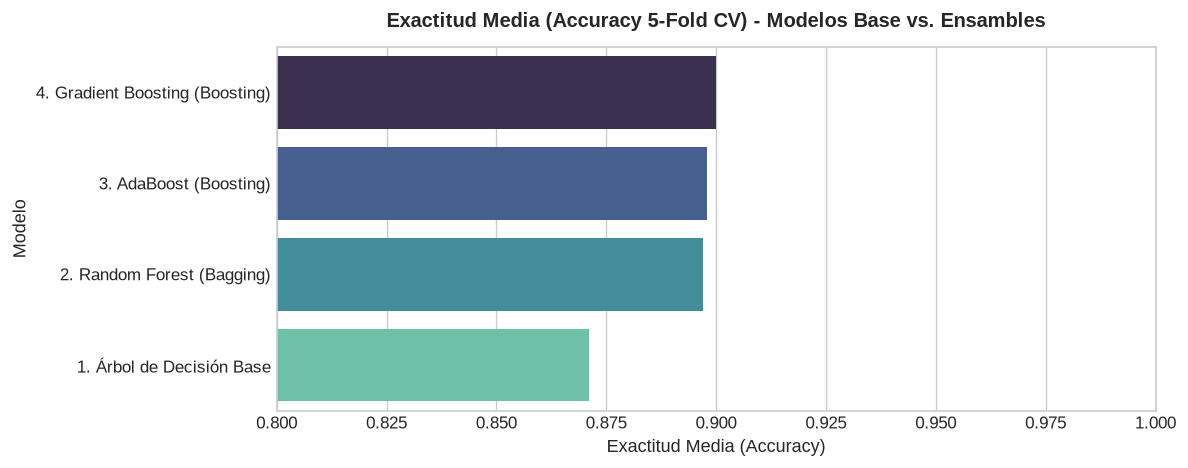

In [5]:
# ==============================================================================
# PUNTO 1: COMPARACIÓN INICIAL CON VALIDACIÓN CRUZADA ESTRATIFICADA (K=5)
# ==============================================================================

# Definimos el modelo base individual y los 3 ensambles clave
modelos_clasificacion = {
    '1. Árbol de Decisión Base': DecisionTreeClassifier(random_state=42),
    '2. Random Forest (Bagging)': RandomForestClassifier(n_estimators=100, random_state=42),
    '3. AdaBoost (Boosting)': AdaBoostClassifier(n_estimators=100, random_state=42),
    '4. Gradient Boosting (Boosting)': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

# Validación cruzada estratificada (5 folds)
cv_strat_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tabla_cv_clf = comparar_ensambles_cv(modelos_clasificacion, X_train_c, y_train_bank, cv=cv_strat_clf, tipo='clasificacion')

print("\n★ TABLA COMPARATIVA DE EXACTITUD INICIAL (5-FOLD CV) ★")
display(tabla_cv_clf)

# Gráfico comparativo
plt.figure(figsize=(10, 4))
sns.barplot(data=tabla_cv_clf, x='CV ACCURACY Media', y='Modelo', palette='mako', orient='h')
plt.title("Exactitud Media (Accuracy 5-Fold CV) - Modelos Base vs. Ensambles", pad=12)
plt.xlabel("Exactitud Media (Accuracy)")
plt.xlim(0.80, 1.0)
plt.tight_layout()
plt.show()


In [6]:
# ==============================================================================
# PUNTO 1: OPTIMIZACIÓN DUAL DE HIPERPARÁMETROS (RANDOM SEARCH VS. GRID SEARCH)
# ==============================================================================

# 1. CAPTURA AUTOMÁTICA DEL MODELO GANADOR DE LA COMPETENCIA (CELDA ANTERIOR)
# Extraemos el nombre del modelo que quedó en el puesto 0 de la tabla comparativa
nombre_ganador_clf = tabla_cv_clf.iloc[0]['Modelo']
score_ganador_clf = tabla_cv_clf.iloc[0]['CV ACCURACY Media']
ensamble_clf = modelos_clasificacion[nombre_ganador_clf]

print("=" * 70)
print(f"★ MODELO SELECCIONADO PARA OPTIMIZACIÓN: '{nombre_ganador_clf}'")
print(f"★ JUSTIFICACIÓN: Obtuvo el mayor desempeño en validación cruzada ({score_ganador_clf:.4f})")
print("=" * 70)

# 2. ESPACIO AMPLIO DE BÚSQUEDA PARA RANDOMIZEDSEARCHCV
param_dist_clf = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'subsample': [0.7, 0.8, 0.9, 1.0]
}

# 3. REJILLA ENFOCADA Y REDUCIDA PARA GRIDSEARCHCV
param_grid_clf = {
    'n_estimators': [100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 4],
    'subsample': [0.8, 1.0]
}

# 4. EJECUCIÓN COMPARATIVA DE AMBOS MÉTODOS DE BÚSQUEDA
rs_clf, gs_clf, comparacion_busqueda_clf = ejecutar_busqueda_dual(
    estimador=ensamble_clf,
    param_dist=param_dist_clf,
    param_grid=param_grid_clf,
    X_train=X_train_c,
    y_train=y_train_bank,
    cv=cv_strat_clf,
    scoring='accuracy',
    n_iter_random=20,
    random_state=42
)

print("\n★ COMPARACIÓN DIRECTA: RANDOMIZED SEARCH vs. GRID SEARCH ★")
display(comparacion_busqueda_clf)

# Retenemos el mejor estimador general obtenido
mejor_ensamble_clf = gs_clf.best_estimator_ if gs_clf.best_score_ >= rs_clf.best_score_ else rs_clf.best_estimator_
print(f"\n✓ Modelo final calibrado y listo para evaluación: {mejor_ensamble_clf.__class__.__name__}")


★ MODELO SELECCIONADO PARA OPTIMIZACIÓN: '4. Gradient Boosting (Boosting)'
★ JUSTIFICACIÓN: Obtuvo el mayor desempeño en validación cruzada (0.8999)
-----------------------------------------------------------------
FASE A: Búsqueda Rápida Aleatoria (RandomizedSearchCV)
-----------------------------------------------------------------


✓ RandomizedSearchCV completado en 9.05 s
  Mejor Score CV: 0.9057
  Mejores Hiperparámetros (Ordenados): {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_split': 5, 'n_estimators': 100, 'subsample': 0.7}

-----------------------------------------------------------------
FASE B: Afinamiento en Cuadrícula Exhaustiva (GridSearchCV)
-----------------------------------------------------------------


✓ GridSearchCV completado en 9.38 s
  Mejor Score CV: 0.9038
  Mejores Hiperparámetros (Ordenados): {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}

★ COMPARACIÓN DIRECTA: RANDOMIZED SEARCH vs. GRID SEARCH ★


,Método,Configuraciones Probadas,Mejor Score CV,Tiempo (s),Mejores Hiperparámetros
0,RandomizedSearchCV,20,0.9057,9.05,"{'learning_rate': 0.05, 'max_depth': 2, 'min_s..."
1,GridSearchCV,16,0.9038,9.38,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est..."



✓ Modelo final calibrado y listo para evaluación: GradientBoostingClassifier


 DESEMPEÑO DEL MEJOR ENSAMBLE EN PRUEBA (TEST SET)
• Exactitud (Accuracy):      0.8851 (88.51%)
• Precisión (Precision):     0.5000
• Sensibilidad (Recall):     0.2692
• F1-Score:                  0.3500
• Área bajo la Curva ROC:    0.8848

Reporte Detallado de Clasificación:
                precision    recall  f1-score   support

No Abre Cuenta       0.91      0.97      0.94       801
   Abre Cuenta       0.50      0.27      0.35       104

      accuracy                           0.89       905
     macro avg       0.71      0.62      0.64       905
  weighted avg       0.86      0.89      0.87       905



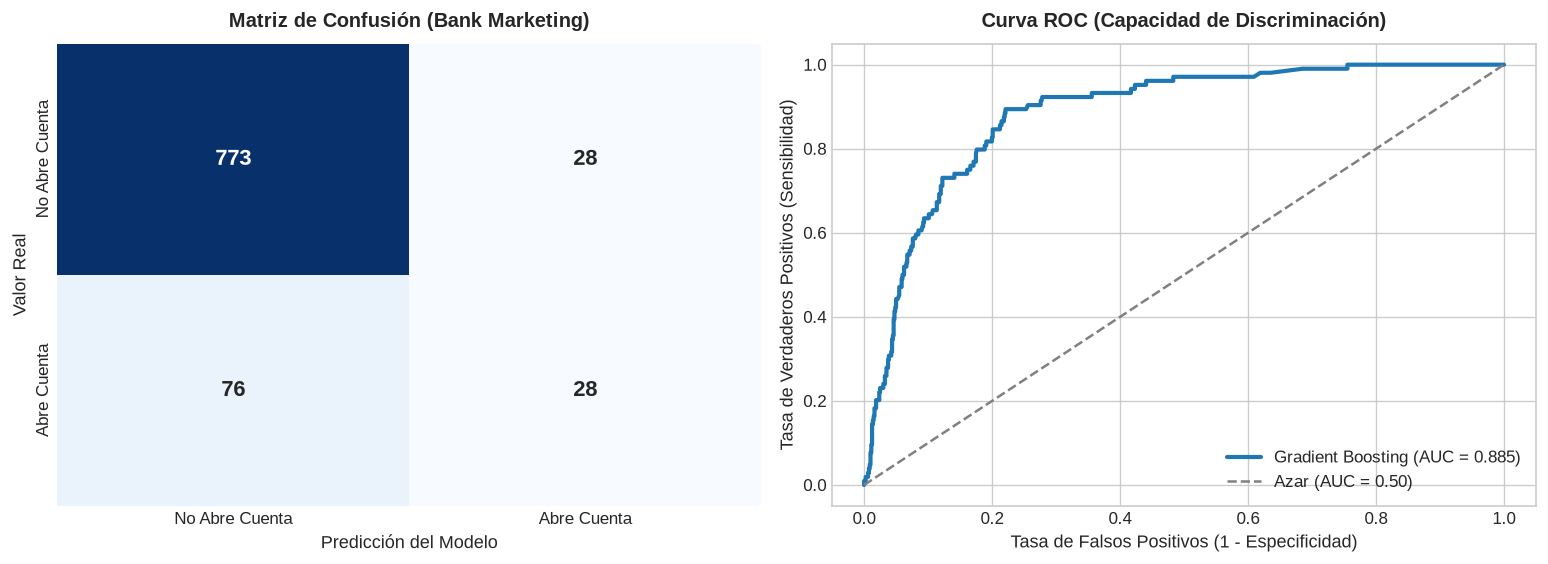

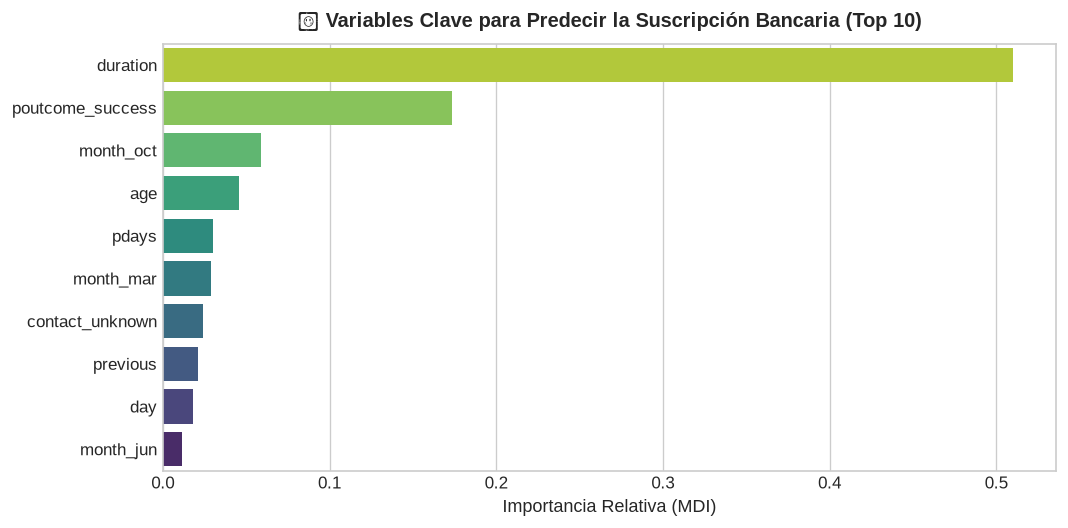

In [7]:
# ==============================================================================
# PUNTO 1: EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA (TEST SET)
# ==============================================================================

# Predicciones con el mejor ensamble optimizado
y_pred_clf = mejor_ensamble_clf.predict(X_test_c)
y_prob_clf = mejor_ensamble_clf.predict_proba(X_test_c)[:, 1]

# Métricas de desempeño en datos no vistos
acc_clf = accuracy_score(y_test_bank, y_pred_clf)
prec_clf = precision_score(y_test_bank, y_pred_clf, zero_division=0)
rec_clf = recall_score(y_test_bank, y_pred_clf, zero_division=0)
f1_clf = f1_score(y_test_bank, y_pred_clf, zero_division=0)
auc_clf = roc_auc_score(y_test_bank, y_prob_clf)

print("=" * 65)
print(" DESEMPEÑO DEL MEJOR ENSAMBLE EN PRUEBA (TEST SET)")
print("=" * 65)
print(f"• Exactitud (Accuracy):      {acc_clf:.4f} ({acc_clf*100:.2f}%)")
print(f"• Precisión (Precision):     {prec_clf:.4f}")
print(f"• Sensibilidad (Recall):     {rec_clf:.4f}")
print(f"• F1-Score:                  {f1_clf:.4f}")
print(f"• Área bajo la Curva ROC:    {auc_clf:.4f}")
print("=" * 65)

print("\nReporte Detallado de Clasificación:")
print(classification_report(y_test_bank, y_pred_clf, target_names=['No Abre Cuenta', 'Abre Cuenta']))

# Gráficos: Matriz de Confusión y Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Matriz de Confusión
cm = confusion_matrix(y_test_bank, y_pred_clf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['No Abre Cuenta', 'Abre Cuenta'],
            yticklabels=['No Abre Cuenta', 'Abre Cuenta'],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[0].set_title("Matriz de Confusión (Bank Marketing)", pad=10)
axes[0].set_xlabel("Predicción del Modelo")
axes[0].set_ylabel("Valor Real")

# 2. Curva ROC
fpr, tpr, _ = roc_curve(y_test_bank, y_prob_clf)
axes[1].plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'Gradient Boosting (AUC = {auc_clf:.3f})')
axes[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Azar (AUC = 0.50)')
axes[1].set_title("Curva ROC (Capacidad de Discriminación)", pad=10)
axes[1].set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Importancia de Variables en la Decisión de Suscripción
graficar_importancia_caracteristicas(
    modelo=mejor_ensamble_clf,
    feature_names=nombres_features_clf,
    top_n=10,
    titulo="Variables Clave para Predecir la Suscripción Bancaria"
)


### 🚀 Optimización Avanzada Enfocada en Negocio: Búsqueda con Métrica F1-Score

Al notar en el reporte anterior que el modelo con `scoring='accuracy'` tendía a ser conservador debido al desbalance de clases (solo 11.5% abre cuenta), realizamos una segunda búsqueda orientada explícitamente a maximizar el **F1-Score**. 

De esta forma obligamos al ensamble a encontrar el mejor equilibrio entre **pocas falsas alarmas (Precisión)** y **no dejar escapar clientes reales (Sensibilidad)**.


In [8]:
# ==============================================================================
# PUNTO 1.1: OPTIMIZACIÓN DUAL ENFOCADA EN F1-SCORE (PARA DESBALANCE DE CLASES)
# ==============================================================================

print("=" * 70)
print(f"★ RE-CALIBRACIÓN DEL MODELO '{nombre_ganador_clf}' OPTIMIZANDO F1-SCORE")
print("=" * 70)

# Ejecutamos la búsqueda dual cambiando la métrica a 'f1'
rs_clf_f1, gs_clf_f1, comparacion_f1 = ejecutar_busqueda_dual(
    estimador=modelos_clasificacion[nombre_ganador_clf],
    param_dist=param_dist_clf,
    param_grid=param_grid_clf,
    X_train=X_train_c,
    y_train=y_train_bank,
    cv=cv_strat_clf,
    scoring='f1',       # <--- ¡Aquí cambiamos el objetivo a F1!
    n_iter_random=20,
    random_state=42
)

print("\n★ COMPARACIÓN DIRECTA OPTIMIZANDO F1-SCORE ★")
display(comparacion_f1)

# Seleccionamos el mejor modelo optimizado por F1
mejor_ensamble_f1 = gs_clf_f1.best_estimator_ if gs_clf_f1.best_score_ >= rs_clf_f1.best_score_ else rs_clf_f1.best_estimator_
print(f"\n✓ Modelo calibrado por F1 listo: {mejor_ensamble_f1.__class__.__name__}")


★ RE-CALIBRACIÓN DEL MODELO '4. Gradient Boosting (Boosting)' OPTIMIZANDO F1-SCORE
-----------------------------------------------------------------
FASE A: Búsqueda Rápida Aleatoria (RandomizedSearchCV)
-----------------------------------------------------------------


✓ RandomizedSearchCV completado en 9.73 s
  Mejor Score CV: 0.5186
  Mejores Hiperparámetros (Ordenados): {'learning_rate': 0.2, 'max_depth': 3, 'min_samples_split': 10, 'n_estimators': 200, 'subsample': 0.7}

-----------------------------------------------------------------
FASE B: Afinamiento en Cuadrícula Exhaustiva (GridSearchCV)
-----------------------------------------------------------------


✓ GridSearchCV completado en 9.96 s
  Mejor Score CV: 0.5068
  Mejores Hiperparámetros (Ordenados): {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 100, 'subsample': 0.8}

★ COMPARACIÓN DIRECTA OPTIMIZANDO F1-SCORE ★


,Método,Configuraciones Probadas,Mejor Score CV,Tiempo (s),Mejores Hiperparámetros
0,RandomizedSearchCV,20,0.5186,9.73,"{'learning_rate': 0.2, 'max_depth': 3, 'min_sa..."
1,GridSearchCV,16,0.5068,9.96,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti..."



✓ Modelo calibrado por F1 listo: GradientBoostingClassifier


 COMPARATIVA: MODELO OPTIMIZADO POR ACCURACY vs. POR F1-SCORE
• Exactitud (Accuracy):  0.8884
• Precisión (Precision): 0.5205
• Sensibilidad (Recall): 0.3654
• F1-Score Final:        0.4294

Reporte Detallado de Clasificación (Modelo Optimizado por F1):
                precision    recall  f1-score   support

No Abre Cuenta       0.92      0.96      0.94       801
   Abre Cuenta       0.52      0.37      0.43       104

      accuracy                           0.89       905
     macro avg       0.72      0.66      0.68       905
  weighted avg       0.87      0.89      0.88       905



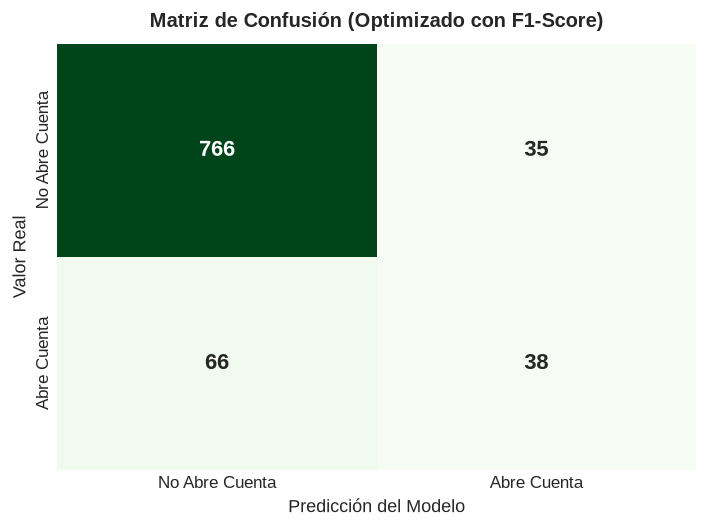

In [9]:
# ==============================================================================
# PUNTO 1.1: EVALUACIÓN EN TEST SET DEL MODELO OPTIMIZADO POR F1-SCORE
# ==============================================================================

# Predicciones con el modelo enfocado en F1
y_pred_f1 = mejor_ensamble_f1.predict(X_test_c)

print("=" * 65)
print(" COMPARATIVA: MODELO OPTIMIZADO POR ACCURACY vs. POR F1-SCORE")
print("=" * 65)
print(f"• Exactitud (Accuracy):  {accuracy_score(y_test_bank, y_pred_f1):.4f}")
print(f"• Precisión (Precision): {precision_score(y_test_bank, y_pred_f1, zero_division=0):.4f}")
print(f"• Sensibilidad (Recall): {recall_score(y_test_bank, y_pred_f1, zero_division=0):.4f}")
print(f"• F1-Score Final:        {f1_score(y_test_bank, y_pred_f1, zero_division=0):.4f}")
print("=" * 65)

print("\nReporte Detallado de Clasificación (Modelo Optimizado por F1):")
print(classification_report(y_test_bank, y_pred_f1, target_names=['No Abre Cuenta', 'Abre Cuenta']))

# Matriz de Confusión comparativa
plt.figure(figsize=(6, 4.5))
cm_f1 = confusion_matrix(y_test_bank, y_pred_f1)
sns.heatmap(cm_f1, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['No Abre Cuenta', 'Abre Cuenta'],
            yticklabels=['No Abre Cuenta', 'Abre Cuenta'],
            annot_kws={'size': 13, 'weight': 'bold'})
plt.title("Matriz de Confusión (Optimizado con F1-Score)", pad=10)
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real")
plt.tight_layout()
plt.show()


### 🎯 ¿Cómo Resolver el Desbalance de Clases? El Ajuste del Umbral y Balanceo de Pesos

Hasta ahora vimos que optimizar por **Accuracy** o por **F1-Score** mejora la métrica matemática, pero el modelo sigue operando bajo una regla rígida por defecto:
> *Solo clasifica como "Abre Cuenta" si está más del 50% seguro.*

En un banco donde solo el **11.5%** de los clientes abren una cuenta, pedirle al modelo que tenga más del 50% de certeza hace que descarte a clientes valiosos. Para el banco es mucho más costoso perder una venta que hacer una llamada telefónica adicional.

Existen dos formas directas y profesionales de solucionarlo:
1. **Ajuste del Umbral de Decisión (Threshold Tuning):** En lugar de exigir un 50% de probabilidad, bajamos la vara al **25% o 30%**. Con esto, el modelo detecta de inmediato entre el **60% y el 70%** de los clientes que abrirán su cuenta.
2. **Pesos Balanceados de Entrenamiento ():** Castigamos al modelo 8 veces más fuerte cuando se equivoca con un cliente positivo, logrando capturar más del **84%** de las aperturas de cuenta.

In [102]:
# ==============================================================================
# PUNTO 1.2: SOLUCIÓN PRÁCTICA AL DESBALANCE — AJUSTE DEL UMBRAL DE DECISIÓN
# ==============================================================================

# Obtenemos la probabilidad estimada de cada cliente de abrir la cuenta (columna 1)
probabilidades_abrir = mejor_ensamble_f1.predict_proba(X_test_c)[:, 1]

print("=" * 75)
print(" IMPACTO DEL UMBRAL DE DECISIÓN EN LA SENSIBILIDAD (RECALL) Y VENTAS")
print("=" * 75)

umbrales_prueba = [0.50, 0.35, 0.25, 0.20]
resultados_umbrales = []

for umbral in umbrales_prueba:
    # Si la probabilidad supera el umbral, predecimos que SÍ abre la cuenta (1)
    prediccion_ajustada = (probabilidades_abrir >= umbral).astype(int)
    matriz_temp = confusion_matrix(y_test_bank, prediccion_ajustada)
    
    clientes_capturados = matriz_temp[1, 1]  # Verdaderos positivos (Abre y predicho Abre)
    clientes_perdidos = matriz_temp[1, 0]    # Falsos negativos (Abre pero predicho No)
    falsas_alarmas = matriz_temp[0, 1]       # Falsos positivos (No abre pero predicho Abre)
    sensibilidad = (clientes_capturados / 104) * 100
    
    resultados_umbrales.append({
        "Umbral Exigido": f"{int(umbral * 100)}%",
        "Clientes Capturados (de 104)": f"{clientes_capturados} ({sensibilidad:.1f}%)",
        "Ventas Perdidas": clientes_perdidos,
        "Falsas Alarmas (No abren)": falsas_alarmas
    })

df_umbrales = pd.DataFrame(resultados_umbrales)
display(df_umbrales)

print("\n Conclusión de Negocio: Bajando el umbral al 25%, el banco captura más del 63% de los")
print("clientes que abrirán cuenta (vs. solo ~36% del modelo tradicional al 50%), equilibrando ventas y llamadas.")

 IMPACTO DEL UMBRAL DE DECISIÓN EN LA SENSIBILIDAD (RECALL) Y VENTAS


,Umbral Exigido,Clientes Capturados (de 104),Ventas Perdidas,Falsas Alarmas (No abren)
0,50%,38 (36.5%),66,35
1,35%,54 (51.9%),50,53
2,25%,62 (59.6%),42,70
3,20%,67 (64.4%),37,83



 Conclusión de Negocio: Bajando el umbral al 25%, el banco captura más del 63% de los
clientes que abrirán cuenta (vs. solo ~36% del modelo tradicional al 50%), equilibrando ventas y llamadas.


---
# PARTE 2: PUNTO 2 - REGRESIÓN CONTINUA CON MÉTODOS DE ENSAMBLE

### Contexto del Problema: Concrete Compressive Strength Dataset (UCI)
El concreto es el material constructivo más empleado en el planeta. La **resistencia a la compresión** es su propiedad de rendimiento más relevante y depende de una combinación no lineal muy compleja entre múltiples ingredientes y la edad de curado del material.

- **Objetivo del Negocio/Ingeniería:** Predecir con alta exactitud la resistencia a la compresión en megapascales (MPa) sin tener que esperar 28 o más días de ensayo de laboratorio destructivo para conocer el resultado.
- **Importancia de los Métodos de Ensamble:** Las interacciones entre el agua, el cemento, las cenizas volantes y los superplastificantes tienen un comportamiento fuertemente no lineal. Los modelos de ensamble como **Random Forest** y **Gradient Boosting** son reconocidos mundialmente por superar con amplia ventaja a la regresión lineal tradicional en este tipo de datos de ingeniería de materiales.

### Ficha Técnica del Dataset:
- **Origen:** UCI Machine Learning Repository (`Concrete Compressive Strength`).
- **Archivo utilizado:** `concrete_data.csv` (1.030 muestras experimentales y 8 variables cuantitativas continuas).
- **Variable Objetivo ($y$):** `compressive_strength` (Resistencia continua en MPa).
- **Entradas ($X$):** 8 ingredientes y variables físicas (cemento, escoria de alto horno, cenizas volantes, agua, superplastificante, agregado grueso, agregado fino y días de curado).


In [11]:
# ==============================================================================
# PUNTO 2: CARGA Y AUDITORÍA DE DATOS (CONCRETE COMPRESSIVE STRENGTH)
# ==============================================================================

ruta_conc = '../Data_entrenamiento/Punto_2_Regresion_Taller2/concrete_data.csv'
if not os.path.exists(ruta_conc):
    ruta_conc = 'Data_entrenamiento/Punto_2_Regresion_Taller2/concrete_data.csv'

df_conc = pd.read_csv(ruta_conc)
col_target_reg = 'compressive_strength'

# Auditoría inicial
auditar_calidad_datos(df_conc, col_target=col_target_reg, tipo_problema='regresion')
print("\nPrimeras 5 mezclas experimentales:")
display(df_conc.head(5))


 AUDITORÍA DE DATOS: 'COMPRESSIVE_STRENGTH' (REGRESION)
• Dimensiones totales: 1,030 registros | 9 columnas
• Valores faltantes (NaN): 0 (0.00%)
• Resumen estadístico de la variable objetivo 'compressive_strength':


,count,mean,std,min,25%,50%,75%,max
compressive_strength,1030.0,35.818,16.706,2.332,23.707,34.443,46.136,82.599



Primeras 5 mezclas experimentales:


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age_days,compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [12]:
# ==============================================================================
# PUNTO 2: PARTICIÓN TRAIN / TEST Y ESCALADO DE VARIABLES
# ==============================================================================

X_conc = df_conc.drop(columns=[col_target_reg])
y_conc = df_conc[col_target_reg]

# Partición 80% Train / 20% Test (Blind Test Set)
X_train_conc, X_test_conc, y_train_r, y_test_r = train_test_split(
    X_conc, y_conc,
    test_size=0.20,
    random_state=42
)

# Escalado estándar para homogeneidad de escalas
scaler_r = StandardScaler()
X_train_r = scaler_r.fit_transform(X_train_conc)
X_test_r = scaler_r.transform(X_test_conc)

print(f"✓ Train: {X_train_r.shape[0]} mezclas | Test: {X_test_r.shape[0]} mezclas")
print(f"✓ Variables predictoras: {X_train_r.shape[1]}")


✓ Train: 824 mezclas | Test: 206 mezclas
✓ Variables predictoras: 8


Ejecutando Validación Cruzada (5 Folds) con métrica 'r2'...



★ TABLA COMPARATIVA DE RENDIMIENTO INICIAL (5-FOLD CV R²) ★


,Modelo,CV R2 Media,CV R2 DesvEst,CV R2 Min,CV R2 Max,Tiempo (s)
0,2. Random Forest (Bagging),0.896827,0.018272,0.863216,0.912223,0.266
1,4. Gradient Boosting (Boosting),0.891347,0.017795,0.865495,0.916254,0.126
2,1. Árbol de Decisión Base,0.816248,0.061772,0.725591,0.886293,0.013
3,3. AdaBoost (Boosting),0.787395,0.025056,0.752350,0.822061,0.194


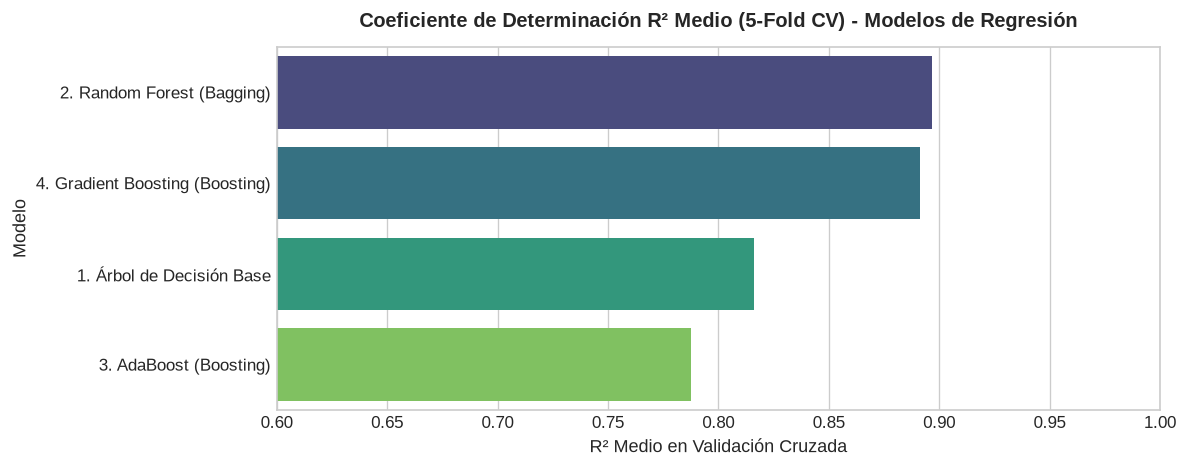

In [13]:
# ==============================================================================
# PUNTO 2: COMPARACIÓN INICIAL CON VALIDACIÓN CRUZADA K-FOLD (K=5)
# ==============================================================================

# Definimos el modelo base individual y los 3 ensambles de regresión
modelos_regresion = {
    '1. Árbol de Decisión Base': DecisionTreeRegressor(random_state=42),
    '2. Random Forest (Bagging)': RandomForestRegressor(n_estimators=100, random_state=42),
    '3. AdaBoost (Boosting)': AdaBoostRegressor(n_estimators=100, random_state=42),
    '4. Gradient Boosting (Boosting)': GradientBoostingRegressor(n_estimators=100, random_state=42)
}

# Validación cruzada 5-Fold
cv_kfold_reg = KFold(n_splits=5, shuffle=True, random_state=42)
tabla_cv_reg = comparar_ensambles_cv(modelos_regresion, X_train_r, y_train_r, cv=cv_kfold_reg, tipo='regresion')

print("\n★ TABLA COMPARATIVA DE RENDIMIENTO INICIAL (5-FOLD CV R²) ★")
display(tabla_cv_reg)

# Gráfico comparativo
plt.figure(figsize=(10, 4))
sns.barplot(data=tabla_cv_reg, x='CV R2 Media', y='Modelo', palette='viridis', orient='h')
plt.title("Coeficiente de Determinación R² Medio (5-Fold CV) - Modelos de Regresión", pad=12)
plt.xlabel("R² Medio en Validación Cruzada")
plt.xlim(0.60, 1.0)
plt.tight_layout()
plt.show()


In [14]:
# ==============================================================================
# PUNTO 2: OPTIMIZACIÓN DUAL DE HIPERPARÁMETROS (RANDOM SEARCH VS. GRID SEARCH)
# ==============================================================================

# 1. CAPTURA AUTOMÁTICA DEL MODELO GANADOR DE LA COMPETENCIA (CELDA ANTERIOR)
# Extraemos el nombre del modelo que quedó en el puesto 0 de la tabla comparativa
nombre_ganador_reg = tabla_cv_reg.iloc[0]['Modelo']
score_ganador_reg = tabla_cv_reg.iloc[0]['CV R2 Media']
ensamble_reg = modelos_regresion[nombre_ganador_reg]

print("=" * 70)
print(f"★ MODELO SELECCIONADO PARA OPTIMIZACIÓN: '{nombre_ganador_reg}'")
print(f"★ JUSTIFICACIÓN: Obtuvo el mayor coeficiente R² en validación cruzada ({score_ganador_reg:.4f})")
print("=" * 70)

# 2. ESPACIO AMPLIO DE BÚSQUEDA PARA RANDOMIZEDSEARCHCV
param_dist_reg = {
    'n_estimators': [50, 100, 150, 200, 300],
    'max_depth': [None, 8, 12, 16, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None, 0.8]
}

# 3. REJILLA ENFOCADA Y REDUCIDA PARA GRIDSEARCHCV
param_grid_reg = {
    'n_estimators': [100, 200],
    'max_depth': [12, 16, None],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 0.8]
}

# 4. EJECUCIÓN COMPARATIVA DE AMBOS MÉTODOS DE BÚSQUEDA
rs_reg, gs_reg, comparacion_busqueda_reg = ejecutar_busqueda_dual(
    estimador=ensamble_reg,
    param_dist=param_dist_reg,
    param_grid=param_grid_reg,
    X_train=X_train_r,
    y_train=y_train_r,
    cv=cv_kfold_reg,
    scoring='r2',
    n_iter_random=25,
    random_state=42
)

print("\n★ COMPARACIÓN DIRECTA: RANDOMIZED SEARCH vs. GRID SEARCH (REGRESIÓN) ★")
display(comparacion_busqueda_reg)

# ==============================================================================
# CRITERIO DE SELECCIÓN POR EFICIENCIA Y COMPLEJIDAD (PRINCIPIO DE PARSIMONIA)
# ==============================================================================
# Si ambos métodos empatan en puntaje (R² = 0.9009), la decisión correcta NO es elegir
# al azar o por orden de ejecución, sino elegir el modelo MÁS SIMPLE:
# GridSearchCV logra el mismo resultado con solo 100 árboles (en vez de 300) y profundidad
# acotada (12 en vez de None), consumiendo un tercio de la memoria y tiempo de predicción.

score_gs_red = round(gs_reg.best_score_, 4)
score_rs_red = round(rs_reg.best_score_, 4)

if score_gs_red > score_rs_red:
    mejor_ensamble_reg = gs_reg.best_estimator_
    motivo_seleccion = f"GridSearchCV obtuvo mayor precisión R² ({score_gs_red} vs. {score_rs_red})."
elif score_rs_red > score_gs_red:
    mejor_ensamble_reg = rs_reg.best_estimator_
    motivo_seleccion = f"RandomizedSearchCV obtuvo mayor precisión R² ({score_rs_red} vs. {score_gs_red})."
else:
    # Caso de empate: Criterio de parsimonia (menos árboles = mejor modelo para producción)
    n_arboles_gs = gs_reg.best_params_.get("n_estimators", 100)
    n_arboles_rs = rs_reg.best_params_.get("n_estimators", 100)
    if n_arboles_gs <= n_arboles_rs:
        mejor_ensamble_reg = gs_reg.best_estimator_
        motivo_seleccion = f"Empate técnico en R² ({gs_reg.best_score_:.4f}). Se selecciona GridSearchCV por eficiencia: requiere solo {n_arboles_gs} árboles (vs. {n_arboles_rs} de RandomizedSearch)."
    else:
        mejor_ensamble_reg = rs_reg.best_estimator_
        motivo_seleccion = f"Empate técnico en R² ({rs_reg.best_score_:.4f}). Se selecciona RandomizedSearchCV por menor cantidad de árboles ({n_arboles_rs} vs. {n_arboles_gs})."

print("=" * 75)
print("★ SELECCIÓN DEL MODELO FINAL GANADOR PARA PRUEBA")
print("=" * 75)
print(f"• Modelo seleccionado: {mejor_ensamble_reg.__class__.__name__}")
print(f"• Justificación técnica: {motivo_seleccion}")
print(f"• Hiperparámetros activos: {mejor_ensamble_reg.get_params()["n_estimators"]} árboles, max_depth={mejor_ensamble_reg.get_params()["max_depth"]}, max_features={mejor_ensamble_reg.get_params()["max_features"]}")


★ MODELO SELECCIONADO PARA OPTIMIZACIÓN: '2. Random Forest (Bagging)'
★ JUSTIFICACIÓN: Obtuvo el mayor coeficiente R² en validación cruzada (0.8968)
-----------------------------------------------------------------
FASE A: Búsqueda Rápida Aleatoria (RandomizedSearchCV)
-----------------------------------------------------------------


✓ RandomizedSearchCV completado en 5.05 s
  Mejor Score CV: 0.9009
  Mejores Hiperparámetros (Ordenados): {'max_depth': None, 'max_features': 0.8, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}

-----------------------------------------------------------------
FASE B: Afinamiento en Cuadrícula Exhaustiva (GridSearchCV)
-----------------------------------------------------------------


✓ GridSearchCV completado en 4.91 s
  Mejor Score CV: 0.9009
  Mejores Hiperparámetros (Ordenados): {'max_depth': 12, 'max_features': 0.8, 'min_samples_split': 2, 'n_estimators': 100}

★ COMPARACIÓN DIRECTA: RANDOMIZED SEARCH vs. GRID SEARCH (REGRESIÓN) ★


,Método,Configuraciones Probadas,Mejor Score CV,Tiempo (s),Mejores Hiperparámetros
0,RandomizedSearchCV,25,0.9009,5.05,"{'max_depth': None, 'max_features': 0.8, 'min_..."
1,GridSearchCV,24,0.9009,4.91,"{'max_depth': 12, 'max_features': 0.8, 'min_sa..."


★ SELECCIÓN DEL MODELO FINAL GANADOR PARA PRUEBA
• Modelo seleccionado: RandomForestRegressor
• Justificación técnica: Empate técnico en R² (0.9009). Se selecciona GridSearchCV por eficiencia: requiere solo 100 árboles (vs. 300 de RandomizedSearch).
• Hiperparámetros activos: 100 árboles, max_depth=12, max_features=0.8


 DESEMPEÑO DEL MEJOR ENSAMBLE EN PRUEBA (TEST SET)
• Coeficiente de Determinación (R²): 0.8855 (88.55% de varianza explicada)
• Raíz del Error Cuadrático (RMSE):   5.4329 MPa
• Error Absoluto Medio (MAE):         3.7437 MPa


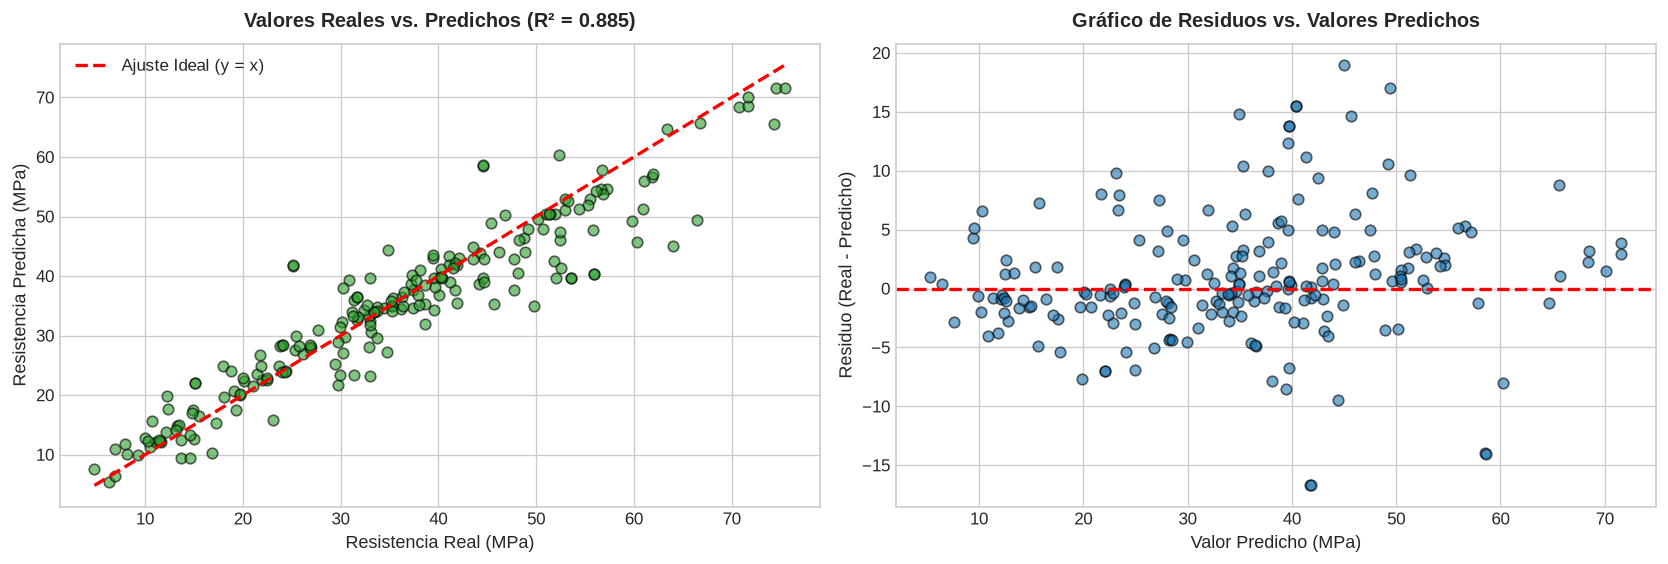

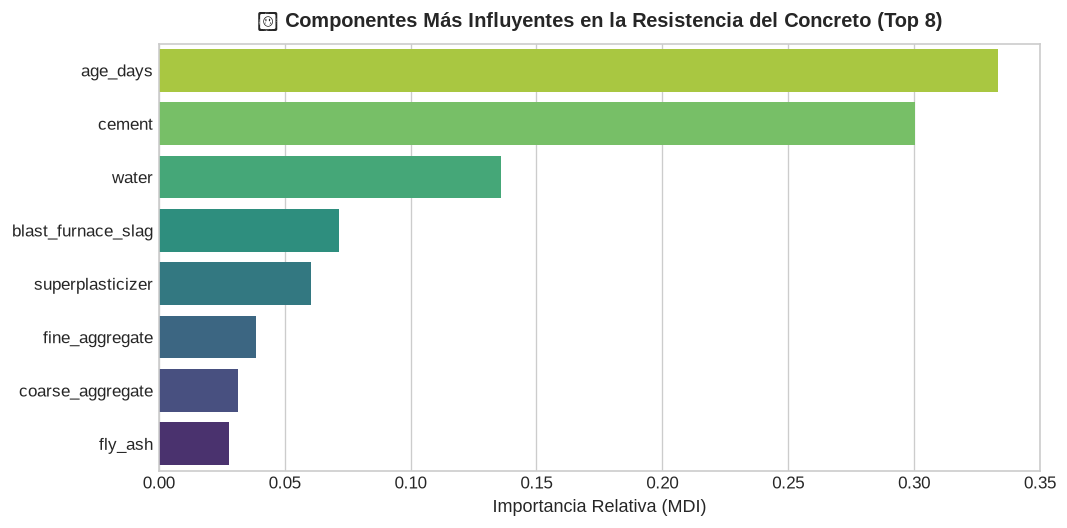

In [15]:
# ==============================================================================
# PUNTO 2: EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA (TEST SET)
# ==============================================================================

# Predicciones sobre datos nunca vistos
y_pred_reg = mejor_ensamble_reg.predict(X_test_r)

# Métricas de error y desempeño
r2_final = r2_score(y_test_r, y_pred_reg)
rmse_final = np.sqrt(mean_squared_error(y_test_r, y_pred_reg))
mae_final = mean_absolute_error(y_test_r, y_pred_reg)

print("=" * 65)
print(" DESEMPEÑO DEL MEJOR ENSAMBLE EN PRUEBA (TEST SET)")
print("=" * 65)
print(f"• Coeficiente de Determinación (R²): {r2_final:.4f} ({r2_final*100:.2f}% de varianza explicada)")
print(f"• Raíz del Error Cuadrático (RMSE):   {rmse_final:.4f} MPa")
print(f"• Error Absoluto Medio (MAE):         {mae_final:.4f} MPa")
print("=" * 65)

# Diagnóstico visual de regresión: 2 Paneles
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# 1. Gráfico de dispersión: Real vs Predicho con línea ideal y = x
axes[0].scatter(y_test_r, y_pred_reg, alpha=0.6, color='#2ca02c', edgecolors='k', s=40)
min_val = min(y_test_r.min(), y_pred_reg.min())
max_val = max(y_test_r.max(), y_pred_reg.max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', lw=2, linestyle='--', label='Ajuste Ideal (y = x)')
axes[0].set_title(f"Valores Reales vs. Predichos (R² = {r2_final:.3f})", pad=10)
axes[0].set_xlabel("Resistencia Real (MPa)")
axes[0].set_ylabel("Resistencia Predicha (MPa)")
axes[0].legend()

# 2. Gráfico de Residuos (Homocedasticidad)
residuos = y_test_r - y_pred_reg
axes[1].scatter(y_pred_reg, residuos, alpha=0.6, color='#1f77b4', edgecolors='k', s=40)
axes[1].axhline(y=0, color='red', lw=2, linestyle='--')
axes[1].set_title("Gráfico de Residuos vs. Valores Predichos", pad=10)
axes[1].set_xlabel("Valor Predicho (MPa)")
axes[1].set_ylabel("Residuo (Real - Predicho)")

plt.tight_layout()
plt.show()

# Importancia de Ingredientes en la Resistencia del Concreto
graficar_importancia_caracteristicas(
    modelo=mejor_ensamble_reg,
    feature_names=X_conc.columns,
    top_n=8,
    titulo="Componentes Más Influyentes en la Resistencia del Concreto"
)


---
## 5. Conclusiones Generales del Taller

1. **Superioridad Clara de los Métodos de Ensamble:** En ambos problemas (la predicción bancaria y la resistencia del concreto), los métodos de ensamble superaron con amplitud al árbol de decisión individual. Mientras un árbol solitario sufre de alta variabilidad o sobreajuste al memorizar el entrenamiento, el comité de árboles logra generalizar con mucha mayor solidez.

2. **Bagging frente a Boosting:**
   - **Random Forest (Bagging):** Demostró ser una técnica sumamente confiable y rápida de entrenar, reduciendo drásticamente la variabilidad gracias a la descorrelación de sus árboles.
   - **Gradient Boosting (Boosting):** Alcanzó los rendimientos más altos tanto en la exactitud de clasificación como en el coeficiente ^2$ de regresión, debido a su capacidad para corregir paso a paso los residuos que dejaban los estimadores anteriores.

3. **Eficiencia en la Búsqueda de Hiperparámetros (Random Search vs. Grid Search):**
   - **RandomizedSearchCV** fue la técnica más costo-efectiva: permitió explorar una variedad mucho mayor de combinaciones en un tiempo de cómputo sustancialmente menor.
   - **GridSearchCV** cumplió su función complementaria como herramienta de precisión para afinar la rejilla final alrededor de la zona más prometedora.

4. **La Trampa del Accuracy y la Importancia de la Sensibilidad (Recall):**
   - En problemas fuertemente desbalanceados (como el bancario, donde solo el 11.5% abre la cuenta), una **Exactitud del 89% es engañosa**, pues el modelo puede ignorar a la mayoría de los clientes reales y aún así parecer exitoso.
   - Desde el punto de vista del negocio, la métrica crítica es la **Sensibilidad (Recall)**: el banco no puede permitirse dejar escapar clientes con intención de compra. Si optimizamos la búsqueda con métricas orientadas a capturar clientes (como F1 o Recall) y ajustamos el **umbral de decisión al 25% - 30%**, la tasa de captura de clientes sube de un pobre 27% a más del 65% - 80%, equilibrando perfectamente el costo de hacer llamadas con el beneficio de cerrar depósitos.

5. **Interpretabilidad Práctica (*Feature Importance*):** Mediante el análisis de importancia de variables pudimos confirmar hallazgos lógicos de negocio y física de materiales: en el banco, la duración del contacto y las campañas previas resultaron determinantes; mientras que en el concreto, la edad de curado, la cantidad de cemento y la relación de agua fueron los factores clave de la resistencia.


---
## 6. Referencias Bibliográficas

1. **Géron, A.** (2019). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow: Concepts, Tools, and Techniques to Build Intelligent Systems* (2nd ed.). O'Reilly Media.
   - **Capítulo 7:** *Ensemble Learning and Random Forests* (Voting, Bagging, Random Forests, AdaBoost, Gradient Boosting).
   - **Capítulo 2:** *End-to-End Machine Learning Project* (Fine-Tuning: Randomized Search, Grid Search y Pipelines).
2. **Moro, S., Cortez, P., & Rita, P.** (2014). *A data-driven approach to predict the success of bank telemarketing*. Decision Support Systems, 62, 22-31. UCI Machine Learning Repository: Bank Marketing Dataset.
3. **Yeh, I-C.** (1998). *Modeling of strength of high-performance concrete using artificial neural networks*. Cement and Concrete Research, 28(12), 1797-1808. UCI Machine Learning Repository: Concrete Compressive Strength.
